In [1]:
from google.colab import drive
from pathlib import Path
import zipfile

drive.mount("/content/drive")

zip_path = Path("/content/drive/MyDrive/pt.zip")
run_dir = Path("/content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh")
weights_dir = run_dir / "weights"

weights_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as z:
    for member in z.infolist():
        if member.is_dir():
            continue

        filename = Path(member.filename).name

        if filename in ("last.pt", "best.pt"):
            with z.open(member) as src, open(weights_dir / filename, "wb") as dst:
                import shutil
                shutil.copyfileobj(src, dst)

print("체크포인트 복원 완료")
print(list(weights_dir.glob("*.pt")))

Mounted at /content/drive
체크포인트 복원 완료
[PosixPath('/content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/weights/best.pt'), PosixPath('/content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/weights/last.pt')]


In [3]:
from pathlib import Path
import zipfile

drive_dir = Path("/content/drive/MyDrive")

for p in drive_dir.rglob("*.zip"):
    print("ZIP:", p)
    with zipfile.ZipFile(p) as z:
        print("내부 파일 예시:")
        for name in z.namelist()[:10]:
            print(" ", name)
    print()

ZIP: /content/drive/MyDrive/pt.zip
내부 파일 예시:
  best.pt
  last.pt

ZIP: /content/drive/MyDrive/tactile_blocks_v4.zip
내부 파일 예시:
  tactile_blocks_v4\images\
  tactile_blocks_v4\labels\
  tactile_blocks_v4\data.yaml
  tactile_blocks_v4\merge_report.csv
  tactile_blocks_v4\images\test\aihub_2_09_0_1_1_1_20210718_0000068367.jpg
  tactile_blocks_v4\images\test\aihub_2_09_0_1_1_1_20210726_0000101526.jpg
  tactile_blocks_v4\images\test\aihub_2_09_0_1_1_1_20210727_0000089549.jpg
  tactile_blocks_v4\images\test\aihub_2_09_0_1_1_1_20210806_0000107041.jpg
  tactile_blocks_v4\images\test\aihub_2_09_0_1_1_1_20210818_0000269247.jpg
  tactile_blocks_v4\images\test\aihub_2_09_0_1_1_1_20210822_0000413524.jpg



In [4]:
from pathlib import Path
import zipfile

zip_path = Path("/content/drive/MyDrive/tactile_blocks_v4.zip")

dataset_dir = Path("/content/datasets/tactile_blocks_v4")
dataset_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as z:
    z.extractall(dataset_dir)

print("압축 해제 완료")

압축 해제 완료


In [5]:
from pathlib import Path
import zipfile
import shutil

zip_path = Path("/content/drive/MyDrive/tactile_blocks_v4.zip")
extract_root = Path("/content/datasets_fixed")

with zipfile.ZipFile(zip_path) as z:
    for member in z.infolist():
        # Windows 경로를 Linux 경로로 변환
        name = member.filename.replace("\\", "/")
        target = extract_root / name

        if member.is_dir() or name.endswith("/"):
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(member) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)

dataset_dir = extract_root / "tactile_blocks_v4"

print("데이터셋:", dataset_dir)
print("존재:", dataset_dir.exists())

for split in ["train", "val", "test"]:
    images = list((dataset_dir / "images" / split).glob("*"))
    labels = list((dataset_dir / "labels" / split).glob("*.txt"))
    print(f"{split}: 이미지 {len(images)}장, 라벨 {len(labels)}개")

데이터셋: /content/datasets_fixed/tactile_blocks_v4
존재: True
train: 이미지 454장, 라벨 454개
val: 이미지 84장, 라벨 84개
test: 이미지 45장, 라벨 45개


In [6]:
import yaml

yaml_path = dataset_dir / "data.yaml"

data = {
    "path": str(dataset_dir),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 2,
    "names": {
        0: "linear",
        1: "dot"
    }
}

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(yaml_path)

/content/datasets_fixed/tactile_blocks_v4/data.yaml


In [7]:
from pathlib import Path

last_pt = Path(
    "/content/drive/MyDrive/TactileCheck/runs/"
    "tactile_v4_fresh/weights/last.pt"
)

print("last.pt 존재:", last_pt.exists())

last.pt 존재: True


In [8]:
!pip install -q ultralytics

In [9]:
from ultralytics import YOLO

model = YOLO(str(last_pt))

model.train(
    resume=True,
    data=str(yaml_path)
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets_fixed/tactile_blocks_v4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torc

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783af33573f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.04104

In [10]:
from pathlib import Path
import pandas as pd

run_dir = Path(
    "/content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh"
)

csv_path = run_dir / "results.csv"

print("학습 결과 폴더 존재:", run_dir.exists())
print("results.csv 존재:", csv_path.exists())

if csv_path.exists():
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    print("기록된 Epoch 수:", len(df))

    columns = [
        "epoch",
        "metrics/precision(M)",
        "metrics/recall(M)",
        "metrics/mAP50(M)",
        "metrics/mAP50-95(M)",
        "train/seg_loss",
        "val/seg_loss"
    ]

    columns = [c for c in columns if c in df.columns]

    metric_col = "metrics/mAP50-95(M)"

    if metric_col in df.columns:
        best_idx = df[metric_col].idxmax()

        print("\n=== Mask mAP50-95 최고 Epoch ===")
        print(df.loc[best_idx, columns].to_string())

        print("\n=== 마지막 Epoch ===")
        print(df.iloc[-1][columns].to_string())

        print("\n=== 최근 10 Epoch 평균 ===")
        print(df.tail(10)[
            [c for c in columns if c != "epoch"]
        ].mean().round(4).to_string())

    else:
        print(df.columns.tolist())

학습 결과 폴더 존재: True
results.csv 존재: True
기록된 Epoch 수: 35

=== Mask mAP50-95 최고 Epoch ===
epoch                   89.00000
metrics/precision(M)     0.95522
metrics/recall(M)        0.94629
metrics/mAP50(M)         0.98510
metrics/mAP50-95(M)      0.87617
train/seg_loss           0.50033
val/seg_loss             0.43300

=== 마지막 Epoch ===
epoch                   100.00000
metrics/precision(M)      0.94077
metrics/recall(M)         0.92076
metrics/mAP50(M)          0.97210
metrics/mAP50-95(M)       0.86114
train/seg_loss            0.41048
val/seg_loss              0.43815

=== 최근 10 Epoch 평균 ===
metrics/precision(M)    0.9661
metrics/recall(M)       0.9188
metrics/mAP50(M)        0.9784
metrics/mAP50-95(M)     0.8563
train/seg_loss          0.4228
val/seg_loss            0.4452


In [11]:
from ultralytics import YOLO
from pathlib import Path

best_pt = run_dir / "weights" / "best.pt"

yaml_path = Path(
    "/content/datasets_fixed/tactile_blocks_v4/data.yaml"
)

assert best_pt.exists(), f"모델 없음: {best_pt}"
assert yaml_path.exists(), f"데이터셋 설정 없음: {yaml_path}"

model = YOLO(str(best_pt))

metrics = model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project=str(run_dir / "evaluation"),
    name="test_eval",
    exist_ok=True
)

print("\n===== v4_fresh TEST 결과 =====")
print(f"Precision    : {metrics.seg.mp:.4f}")
print(f"Recall       : {metrics.seg.mr:.4f}")
print(f"Mask mAP50   : {metrics.seg.map50:.4f}")
print(f"Mask mAP50-95: {metrics.seg.map:.4f}")

print("\n클래스별 Mask mAP50-95")
for i, value in enumerate(metrics.seg.maps):
    print(f"{model.names[i]}: {value:.4f}")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,366 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 823.8±131.7 MB/s, size: 936.7 KB)
val: Scanning /content/datasets_fixed/tactile_blocks_v4/labels/test... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 509.9it/s 0.1s
val: New cache created: /content/datasets_fixed/tactile_blocks_v4/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.0s/it 6.1s
                   all         45        119       0.97      0.906      0.917      0.811      0.955      0.892      0.917      0.828
                linear         41         83      0.952      0.867      0.854      0.755      0.952      0.867      0.873      0.761
                   dot         30         36      0.988      0.944      0.979  

Saving KakaoTalk_20261112_002800737_06.jpg to KakaoTalk_20261112_002800737_06.jpg
Saving KakaoTalk_20261112_002800737_07.jpg to KakaoTalk_20261112_002800737_07.jpg
Saving KakaoTalk_20261112_002800737_08.jpg to KakaoTalk_20261112_002800737_08.jpg
Saving KakaoTalk_20261112_002800737_09.jpg to KakaoTalk_20261112_002800737_09.jpg
Saving KakaoTalk_20261112_002800737_10.jpg to KakaoTalk_20261112_002800737_10.jpg
Saving KakaoTalk_20261112_002800737_11.jpg to KakaoTalk_20261112_002800737_11.jpg
Saving KakaoTalk_20261112_002800737_02.jpg to KakaoTalk_20261112_002800737_02.jpg
Saving KakaoTalk_20261112_002800737_03.jpg to KakaoTalk_20261112_002800737_03.jpg
Saving KakaoTalk_20261112_002800737_04.jpg to KakaoTalk_20261112_002800737_04.jpg
Saving KakaoTalk_20261112_002800737_05.jpg to KakaoTalk_20261112_002800737_05.jpg
Saving KakaoTalk_20261112_002800737.jpg to KakaoTalk_20261112_002800737.jpg
Saving KakaoTalk_20261112_002800737_01.jpg to KakaoTalk_20261112_002800737_01.jpg


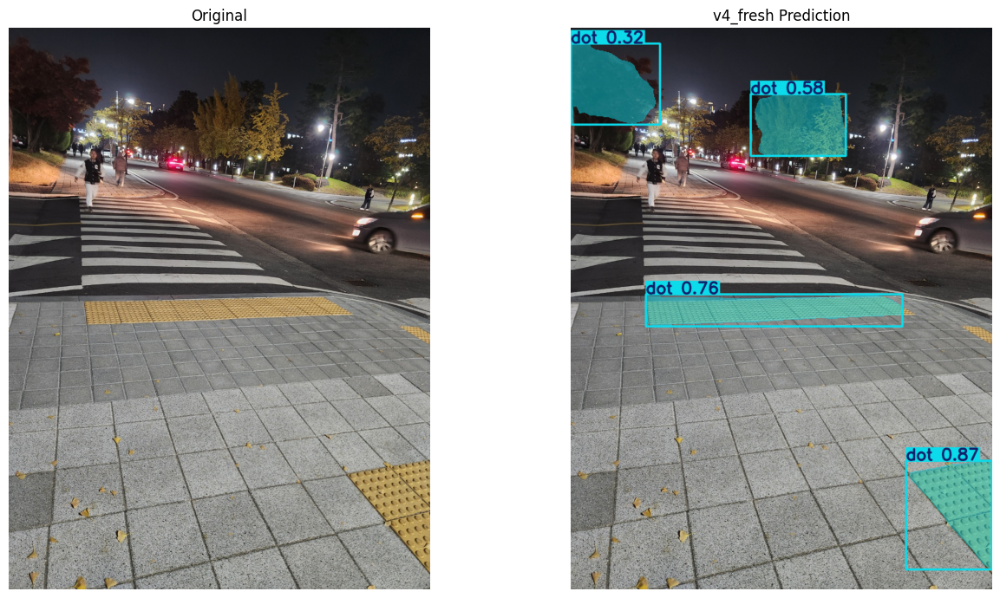

KakaoTalk_20261112_002800737_06.jpg: 검출 객체 4개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_06.png


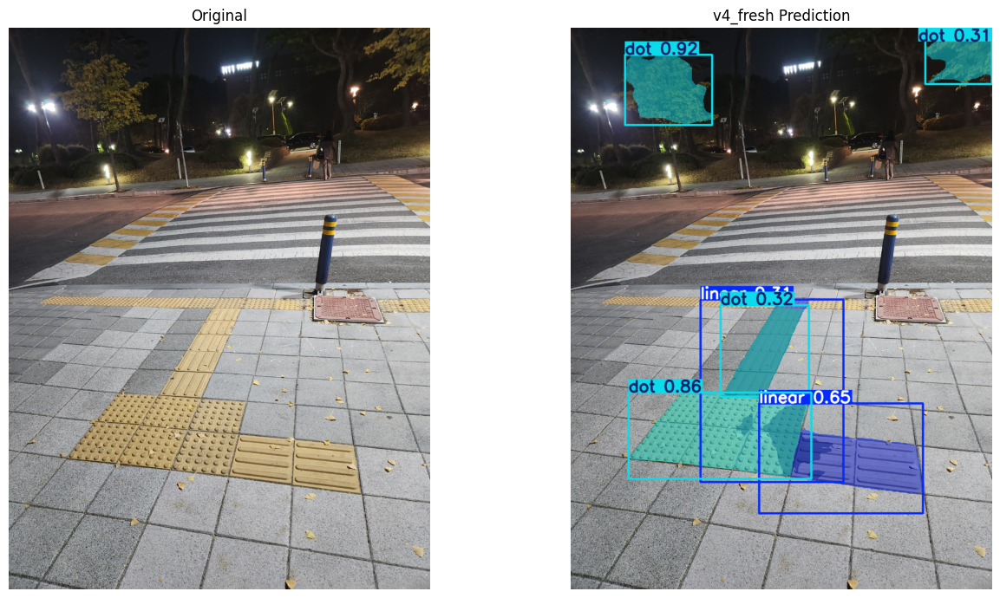

KakaoTalk_20261112_002800737_07.jpg: 검출 객체 6개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_07.png


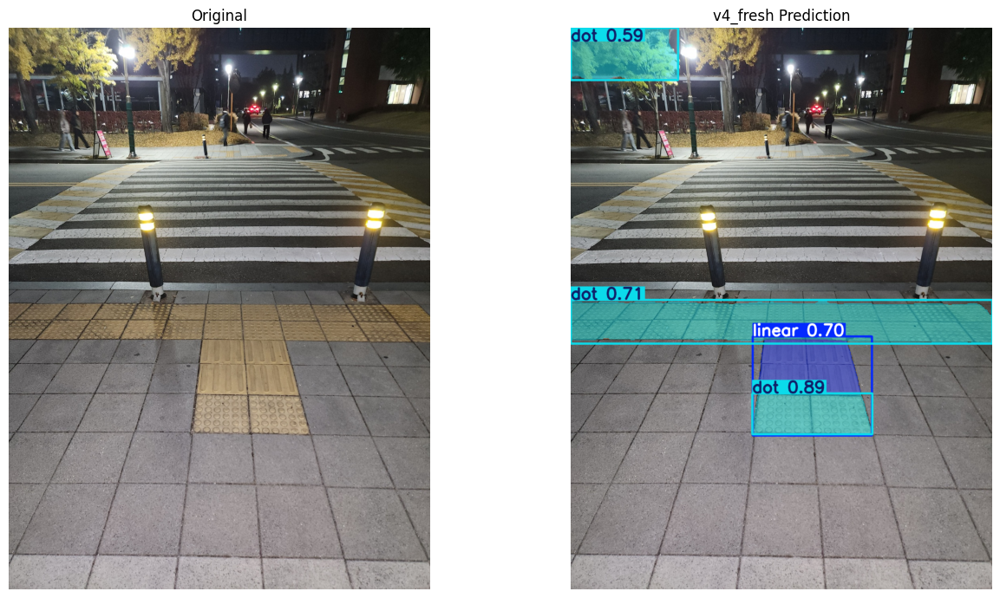

KakaoTalk_20261112_002800737_08.jpg: 검출 객체 4개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_08.png


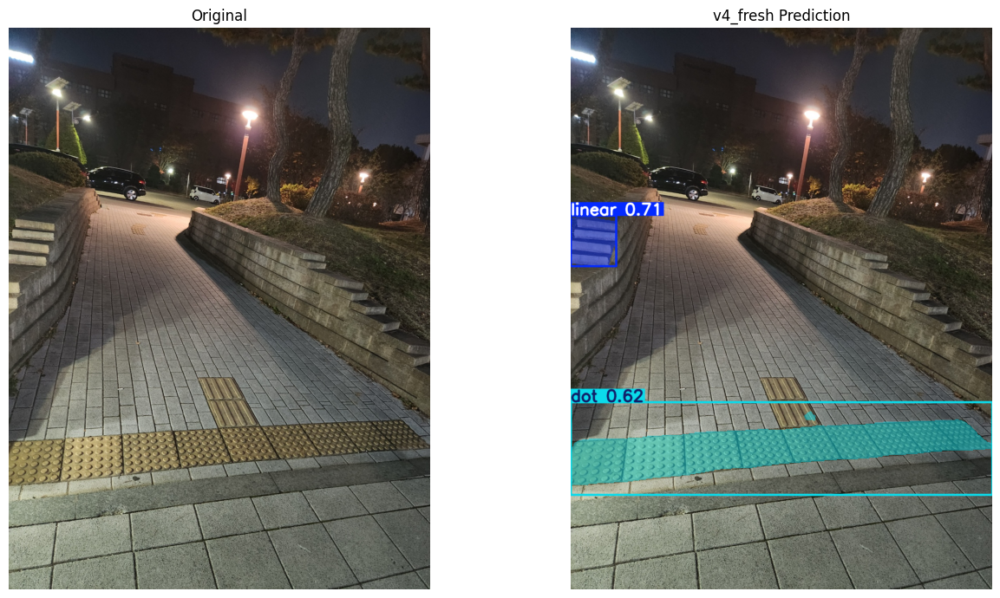

KakaoTalk_20261112_002800737_09.jpg: 검출 객체 2개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_09.png


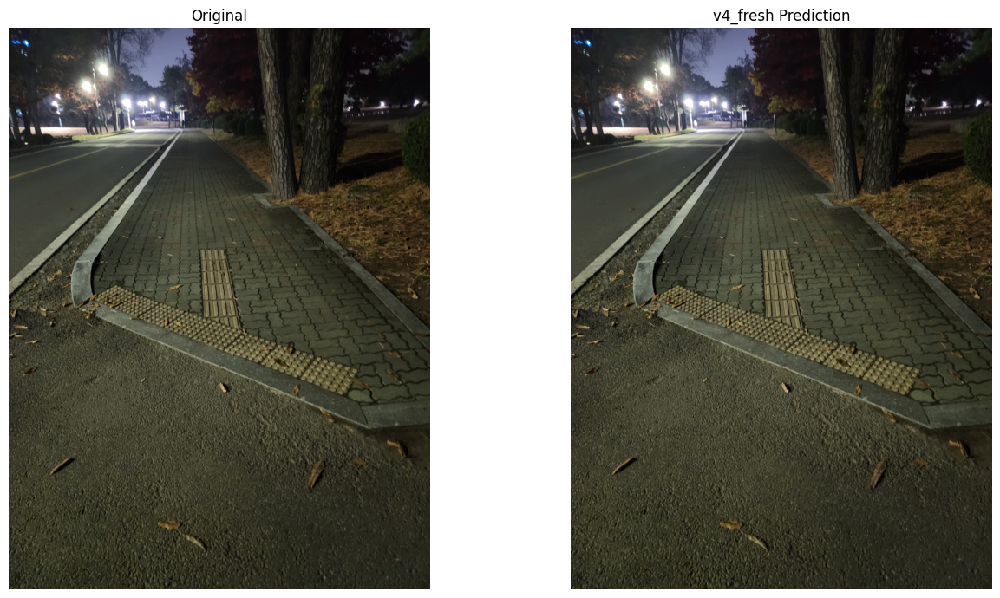

KakaoTalk_20261112_002800737_10.jpg: 검출 객체 0개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_10.png


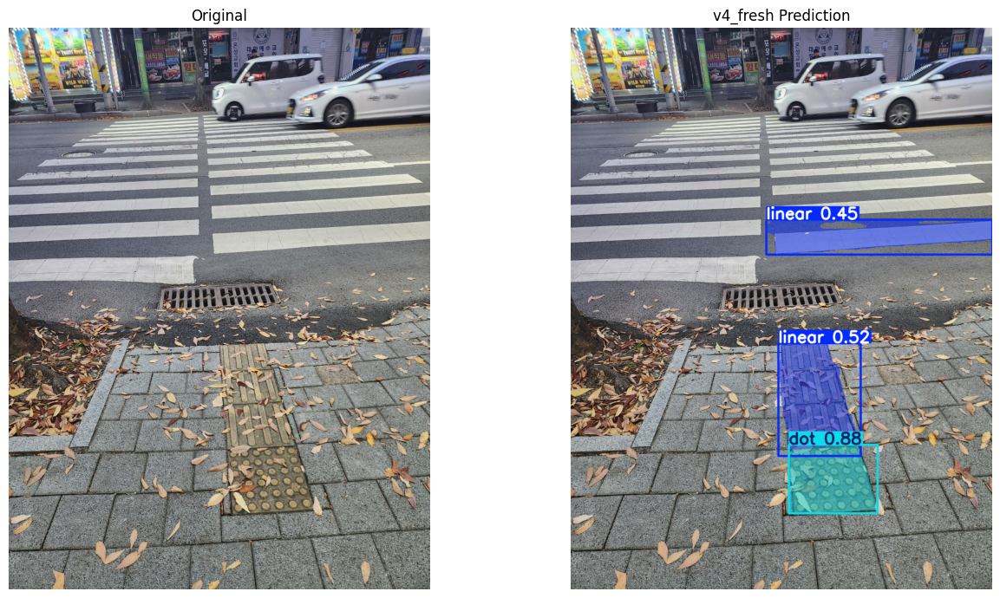

KakaoTalk_20261112_002800737_11.jpg: 검출 객체 3개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_11.png


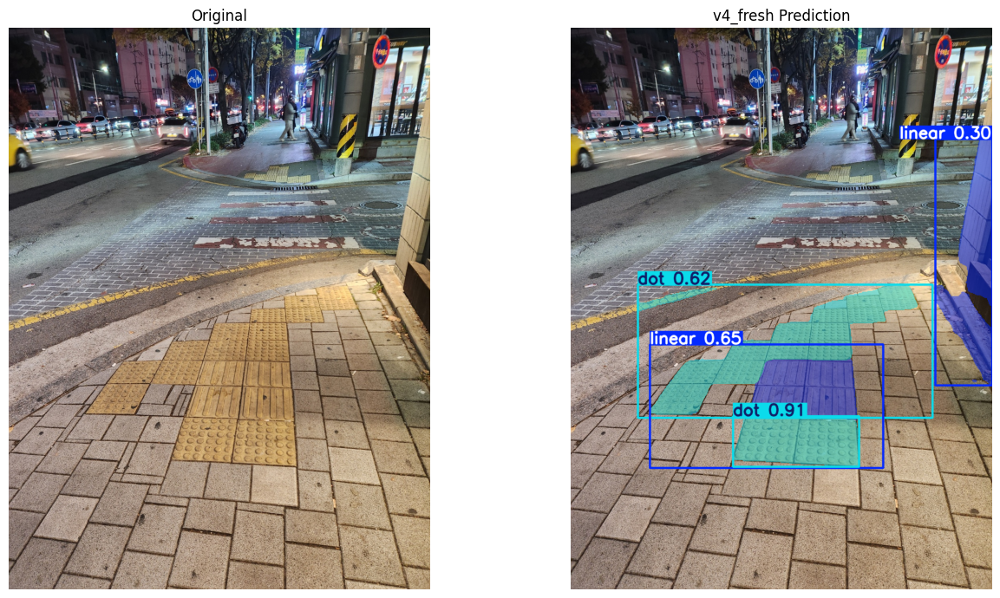

KakaoTalk_20261112_002800737_02.jpg: 검출 객체 4개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_02.png


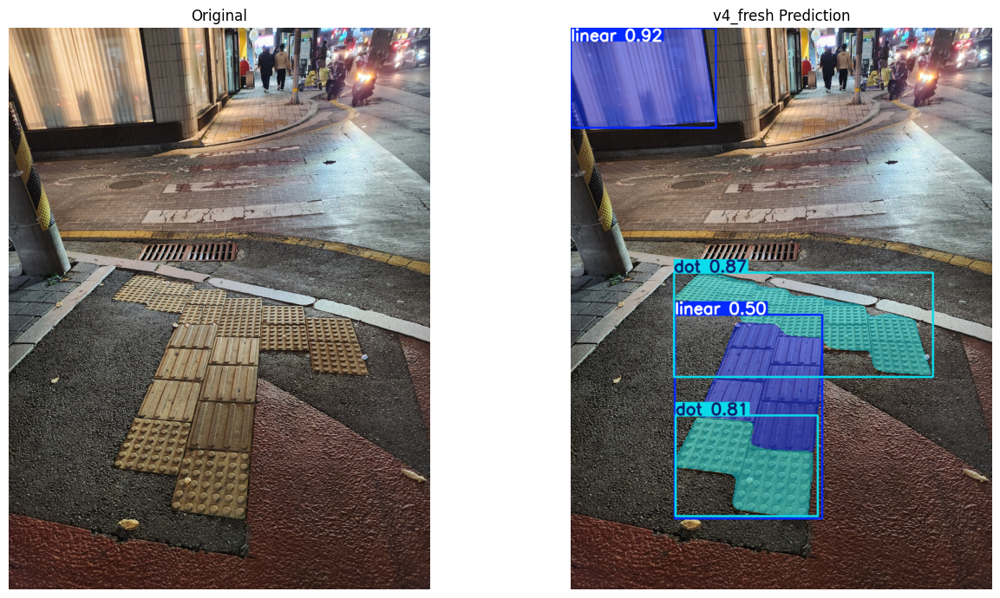

KakaoTalk_20261112_002800737_03.jpg: 검출 객체 4개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_03.png


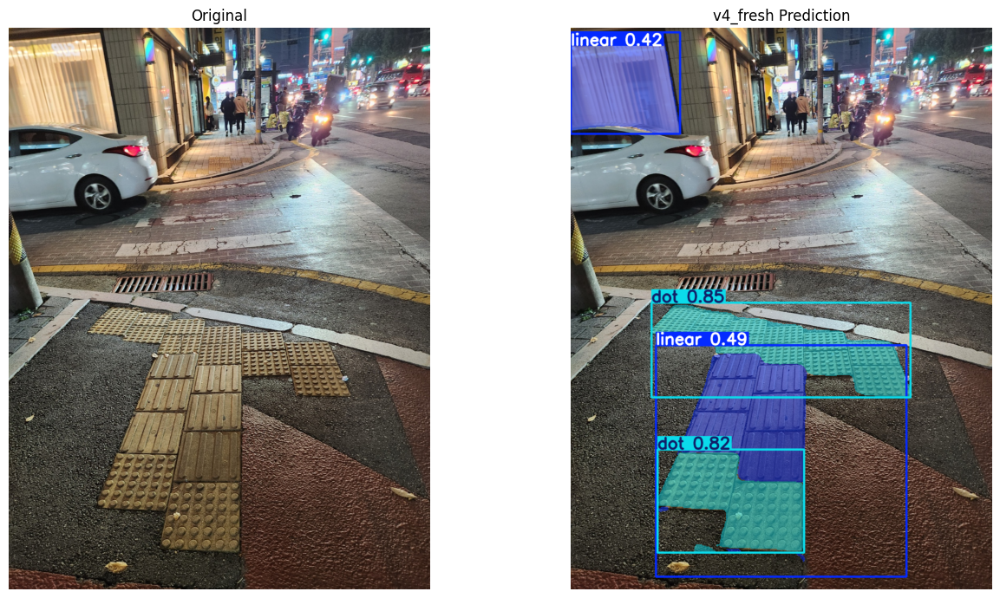

KakaoTalk_20261112_002800737_04.jpg: 검출 객체 4개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_04.png


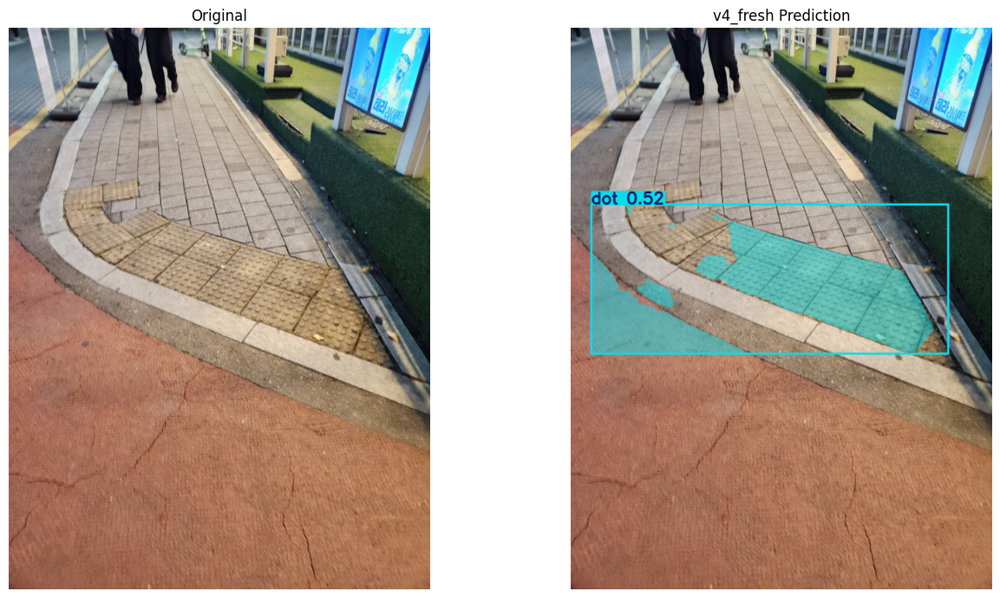

KakaoTalk_20261112_002800737_05.jpg: 검출 객체 1개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_05.png


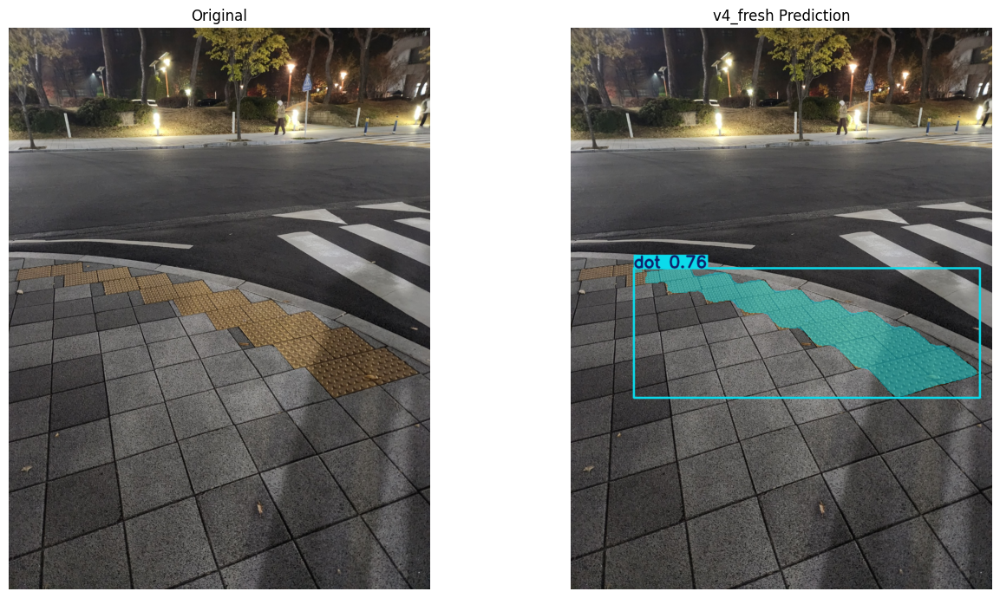

KakaoTalk_20261112_002800737.jpg: 검출 객체 1개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737.png


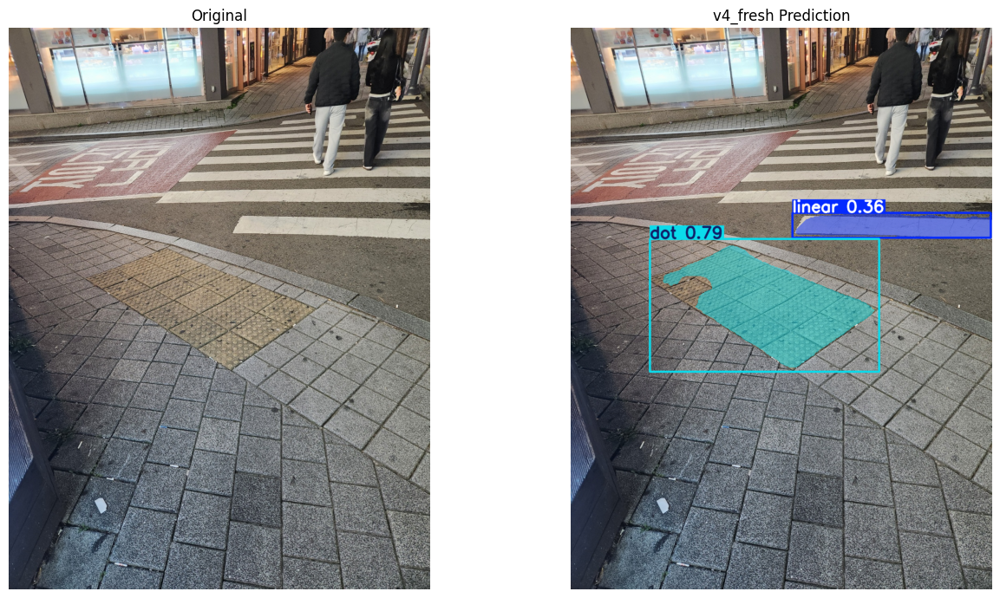

KakaoTalk_20261112_002800737_01.jpg: 검출 객체 2개
저장: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/real_test/result_KakaoTalk_20261112_002800737_01.png


In [12]:
from ultralytics import YOLO
from google.colab import files
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

best_pt = (
    "/content/drive/MyDrive/TactileCheck/"
    "runs/tactile_v4_fresh/weights/best.pt"
)

model = YOLO(best_pt)

save_dir = Path(
    "/content/drive/MyDrive/TactileCheck/"
    "runs/tactile_v4_fresh/real_test"
)
save_dir.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

for filename, content in uploaded.items():
    image_path = save_dir / Path(filename).name
    image_path.write_bytes(content)

    original = cv2.imread(str(image_path))

    if original is None:
        print("이미지 읽기 실패:", filename)
        continue

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    overlay = result.plot()

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title("Original")

    axes[1].imshow(
        cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
    )
    axes[1].set_title("v4_fresh Prediction")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    output_path = save_dir / f"result_{Path(filename).stem}.png"
    cv2.imwrite(str(output_path), overlay)

    print(f"{filename}: 검출 객체 {len(result.boxes)}개")
    print("저장:", output_path)

In [13]:
from pathlib import Path
from ultralytics import YOLO

drive_root = Path("/content/drive/MyDrive")

# 루트에 업로드한 v3 모델
candidates = [
    drive_root / "v3 best.pt",
    drive_root / "best.pt",
    drive_root / "v3_best.pt",
]

v3_pt = next((p for p in candidates if p.exists()), None)

if v3_pt is None:
    raise FileNotFoundError(
        f"v3 모델을 찾을 수 없음. 루트 PT 파일: "
        f"{list(drive_root.glob('*.pt'))}"
    )

# 기존 v4_fresh 모델
fresh_pt = (
    drive_root / "TactileCheck/runs/"
    "tactile_v4_fresh/weights/best.pt"
)

assert fresh_pt.exists(), f"v4_fresh 모델 없음: {fresh_pt}"

models = {
    "v3": YOLO(str(v3_pt)),
    "v4_fresh": YOLO(str(fresh_pt)),
}

print("v3:", v3_pt)
print("v4_fresh:", fresh_pt)

v3: /content/drive/MyDrive/best.pt
v4_fresh: /content/drive/MyDrive/TactileCheck/runs/tactile_v4_fresh/weights/best.pt


In [14]:
import pandas as pd

yaml_path = "/content/datasets_fixed/tactile_blocks_v4/data.yaml"

rows = []

for name, model in models.items():
    print(f"\n===== {name} 평가 =====")

    m = model.val(
        data=yaml_path,
        split="test",
        imgsz=640,
        batch=8,
        device=0,
        plots=False
    )

    rows.append({
        "모델": name,
        "Precision": m.seg.mp,
        "Recall": m.seg.mr,
        "mAP50": m.seg.map50,
        "mAP50-95": m.seg.map,
        "Linear mAP50-95": m.seg.maps[0],
        "Dot mAP50-95": m.seg.maps[1],
    })

comparison = pd.DataFrame(rows)

display(comparison.round(4))


===== v3 평가 =====
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,366 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1727.8±488.1 MB/s, size: 46.5 KB)
val: Scanning /content/datasets_fixed/tactile_blocks_v4/labels/test.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 7.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.8it/s 3.3s
                   all         45        119      0.923      0.915      0.925      0.808      0.909      0.902      0.911       0.83
                linear         41         83      0.901       0.88      0.877      0.771        0.9       0.88      0.861      0.766
                   dot         30         36      0.945      0.951      0.973      0.845      0.917      0.924      0.962      0.894
Speed:

,모델,Precision,Recall,mAP50,mAP50-95,Linear mAP50-95,Dot mAP50-95
0,v3,0.9088,0.9019,0.9113,0.8303,0.7661,0.8944
1,v4_fresh,0.9553,0.8921,0.9166,0.8285,0.7614,0.8956


비교 사진: 12


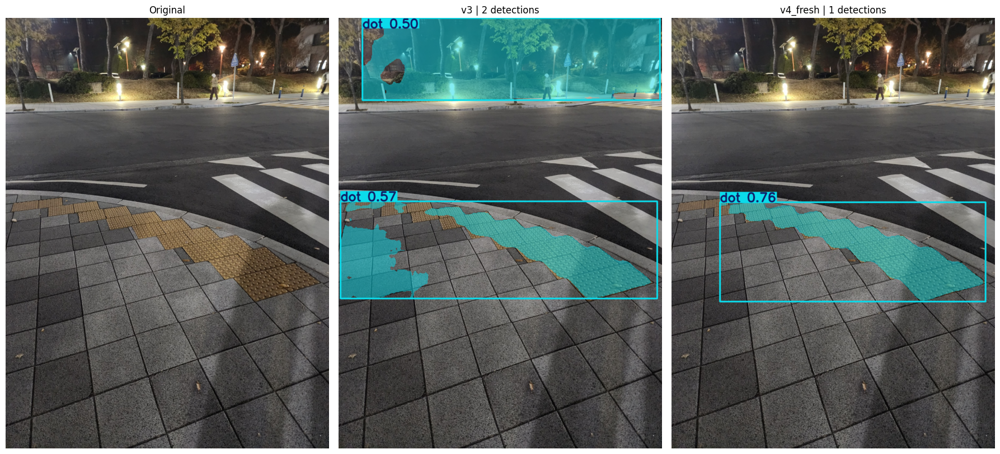

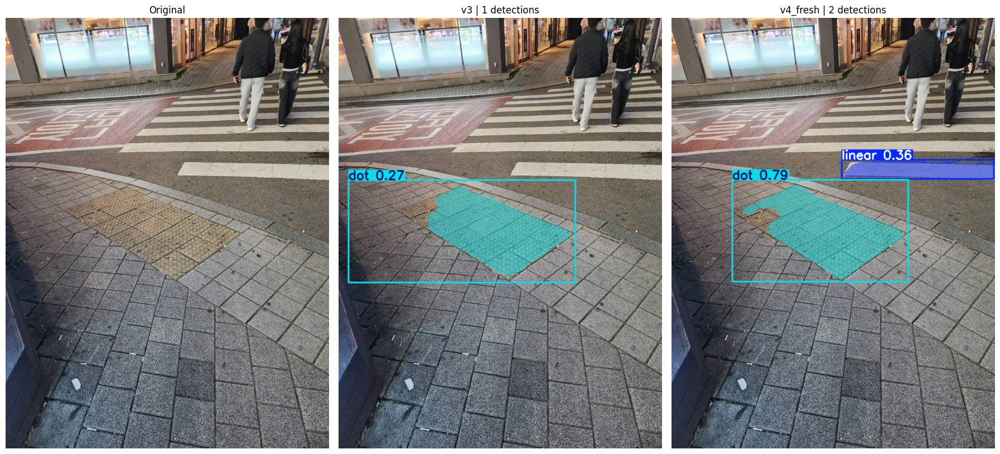

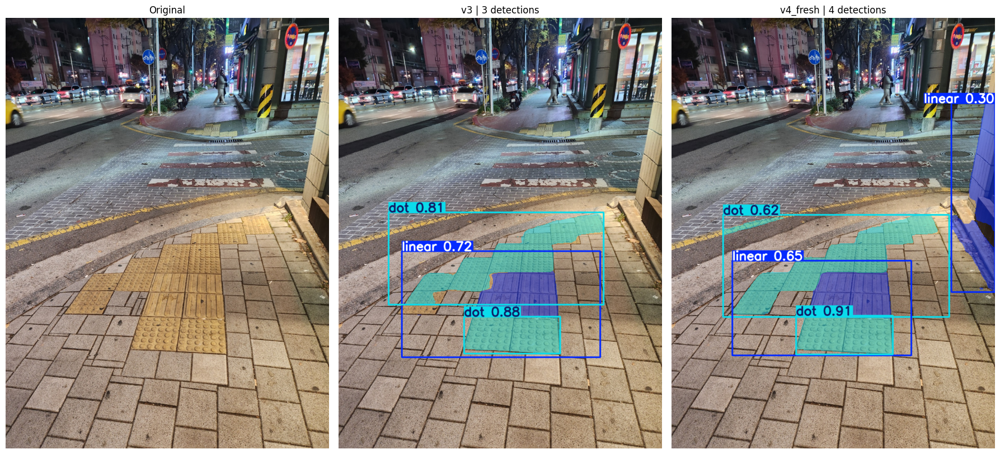

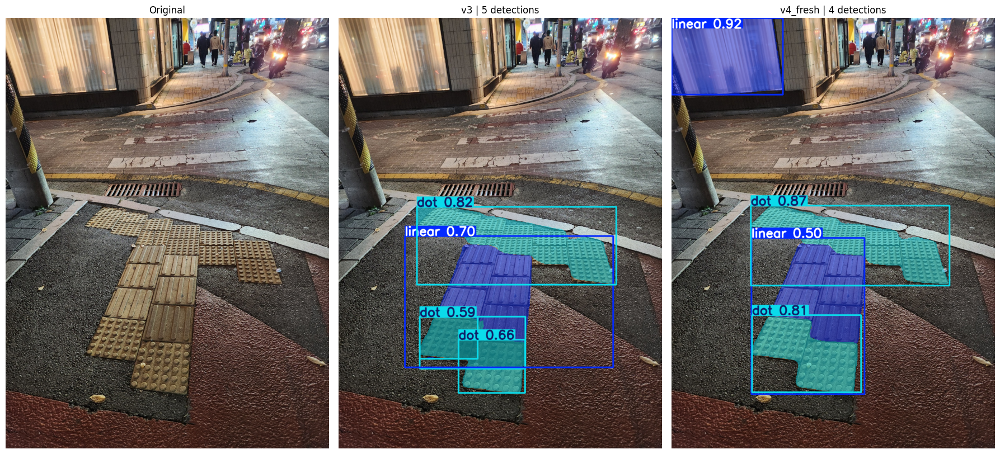

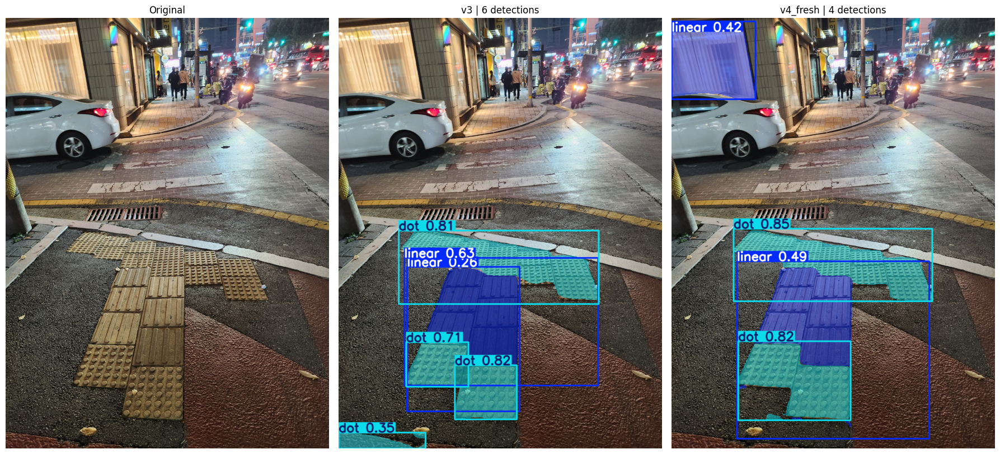

...

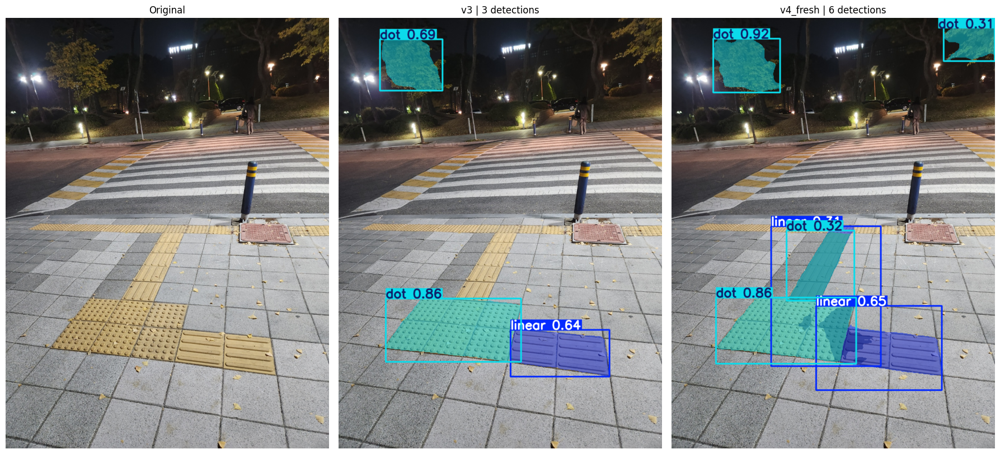

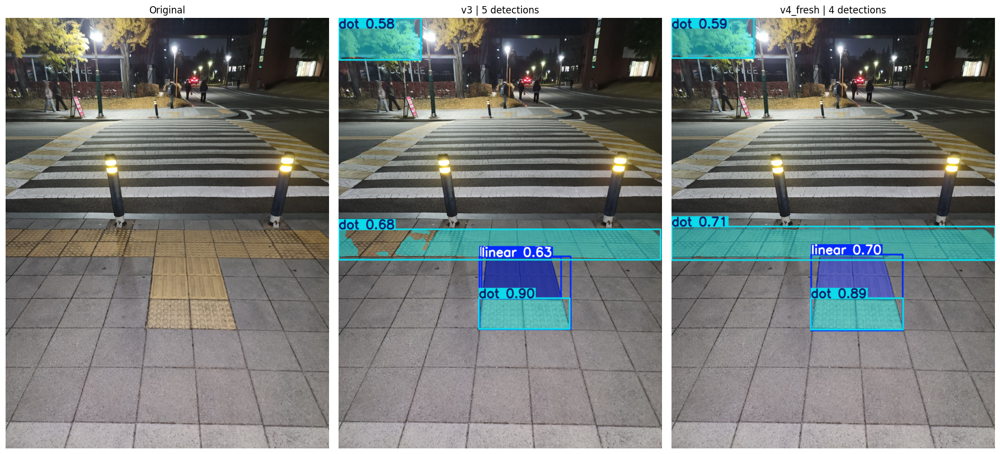

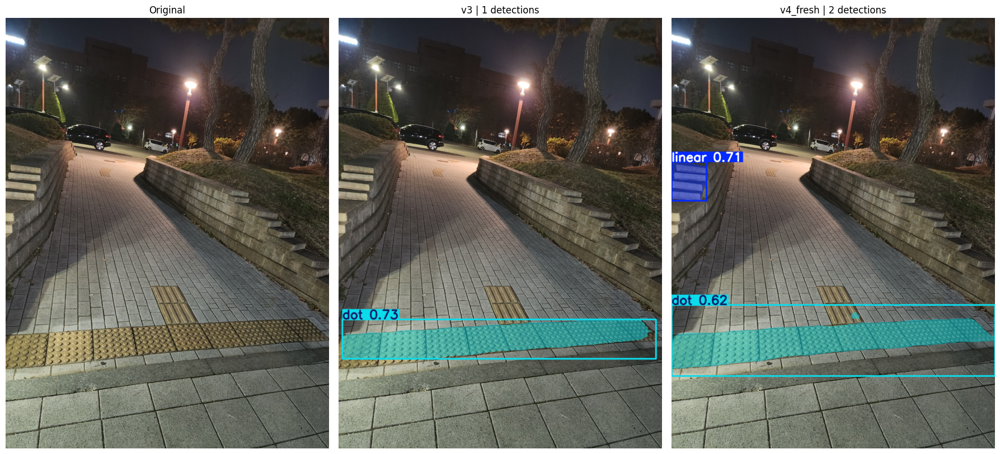

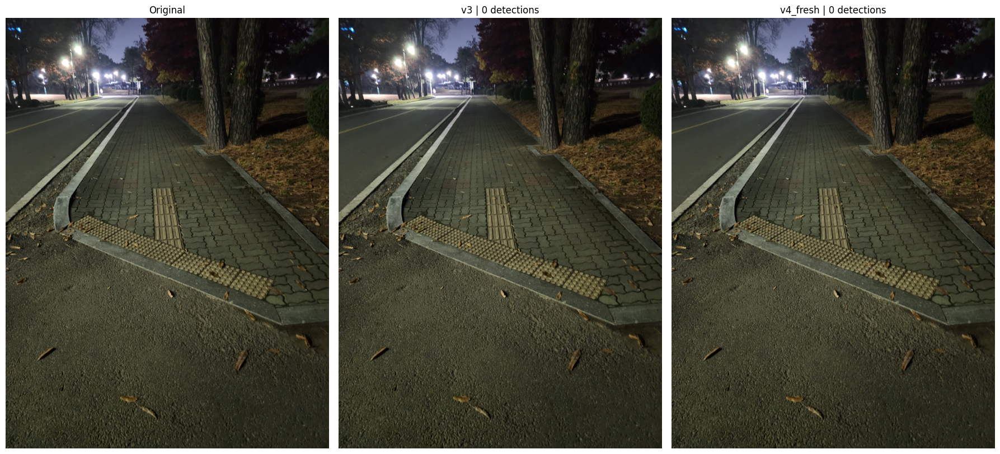

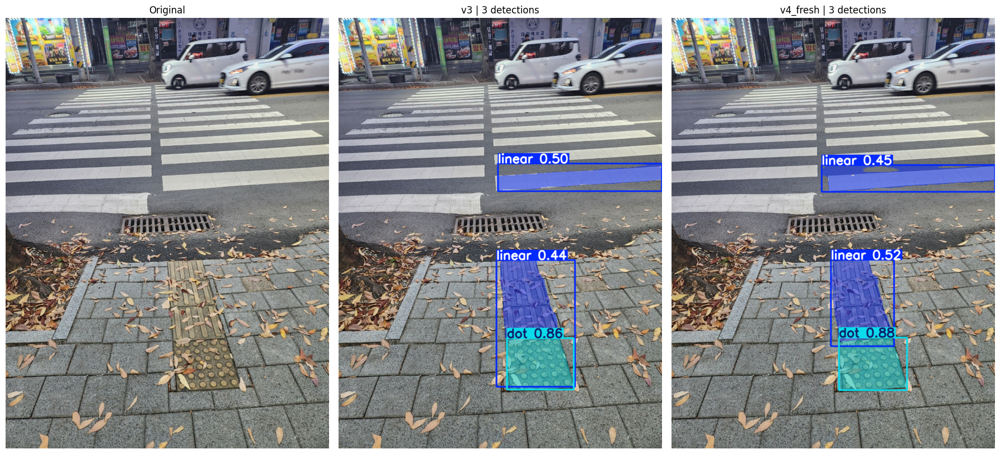

저장 경로: /content/drive/MyDrive/TactileCheck/runs/model_comparison


In [15]:
import cv2
import matplotlib.pyplot as plt

base = drive_root / "TactileCheck/runs"

real_dir = base / "tactile_v4_fresh/real_test"
output_dir = base / "model_comparison"
output_dir.mkdir(parents=True, exist_ok=True)

images = sorted([
    p for p in real_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    and not p.name.startswith("result_")
])

print("비교 사진:", len(images))

for image_path in images:
    original = cv2.imread(str(image_path))
    if original is None:
        continue

    fig, axes = plt.subplots(1, 3, figsize=(18, 8))

    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original")

    for i, (name, model) in enumerate(models.items(), start=1):
        result = model.predict(
            source=str(image_path),
            imgsz=640,
            conf=0.25,
            verbose=False
        )[0]

        overlay = result.plot()

        axes[i].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[i].set_title(
            f"{name} | {len(result.boxes)} detections"
        )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()

    save_path = output_dir / f"compare_{image_path.stem}.png"
    plt.savefig(save_path, dpi=120, bbox_inches="tight")

    plt.show()
    plt.close()

print("저장 경로:", output_dir)